In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score

data = pd.read_csv("dataset/uber.csv")

In [10]:
data = data.drop(['Unnamed: 0', 'key'], axis=1)
data['pickup_datetime'] = pd.to_datetime(data['pickup_datetime'], errors='coerce')
data = data.dropna(subset=['pickup_datetime'])

data['hour'] = data['pickup_datetime'].dt.hour
data['day'] = data['pickup_datetime'].dt.day
data['month'] = data['pickup_datetime'].dt.month
data['year'] = data['pickup_datetime'].dt.year
data = data.drop(['pickup_datetime'], axis=1)

data = data[(data['fare_amount'] > 0) & (data['fare_amount'] < 500)]
data = data[(data['passenger_count'] > 0) & (data['passenger_count'] <= 6)]
data = data[(data['pickup_longitude'].between(-75, -72)) & (data['pickup_latitude'].between(40, 42))]
data = data[(data['dropoff_longitude'].between(-75, -72)) & (data['dropoff_latitude'].between(40, 42))]

def haversine_distance(lat1, lon1, lat2, lon2):
    R = 6371
    phi1 = np.radians(lat1)
    phi2 = np.radians(lat2)
    delta_phi = np.radians(lat2 - lat1)
    delta_lambda = np.radians(lon2 - lon1)
    a = np.sin(delta_phi / 2)**2 + np.cos(phi1) * np.cos(phi2) * np.sin(delta_lambda / 2)**2
    c = 2 * np.arctan2(np.sqrt(a), np.sqrt(1 - a))
    return R * c

data['distance_km'] = haversine_distance(
    data['pickup_latitude'], data['pickup_longitude'],
    data['dropoff_latitude'], data['dropoff_longitude']
)

data = data.drop(['pickup_latitude', 'pickup_longitude', 'dropoff_latitude', 'dropoff_longitude'], axis=1)

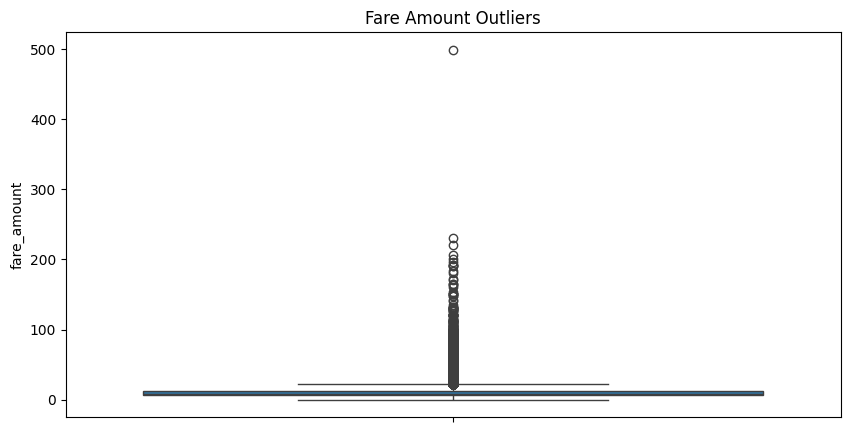

In [11]:
plt.figure(figsize=(10, 5))
sns.boxplot(data['fare_amount'])
plt.title('Fare Amount Outliers')
plt.show()

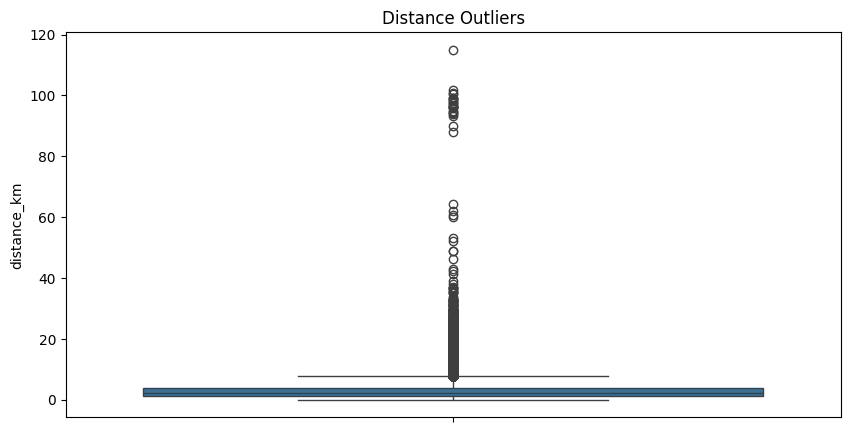

In [12]:
plt.figure(figsize=(10, 5))
sns.boxplot(data['distance_km'])
plt.title('Distance Outliers')
plt.show()

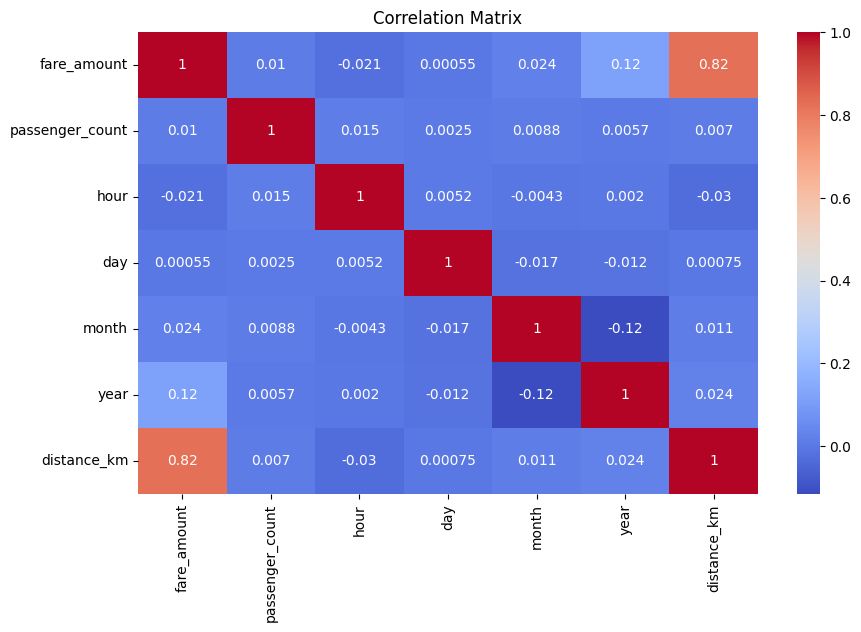

In [13]:
plt.figure(figsize=(10, 6))
sns.heatmap(data.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

In [14]:
X = data.drop('fare_amount', axis=1)
y = data['fare_amount']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [15]:
lr = LinearRegression()
lr.fit(X_train_scaled, y_train)
y_pred_lr = lr.predict(X_test_scaled)

ridge = Ridge(alpha=1.0)
ridge.fit(X_train_scaled, y_train)
y_pred_ridge = ridge.predict(X_test_scaled)

lasso = Lasso(alpha=0.1)
lasso.fit(X_train_scaled, y_train)
y_pred_lasso = lasso.predict(X_test_scaled)


def evaluate(y_test, y_pred, model_name):
  rmse = np.sqrt(mean_squared_error(y_test, y_pred))
  r2 = r2_score(y_test, y_pred)
  print(f"{model_name} -> RMSE: {rmse:.2f}, R2: {r2:.2f}")


evaluate(y_test, y_pred_lr, "Linear Regression")
evaluate(y_test, y_pred_ridge, "Ridge Regression")
evaluate(y_test, y_pred_lasso, "Lasso Regression")

results = pd.DataFrame({
    'Model': ['Linear Regression', 'Ridge Regression', 'Lasso Regression'],
    'RMSE': [
        np.sqrt(mean_squared_error(y_test, y_pred_lr)),
        np.sqrt(mean_squared_error(y_test, y_pred_ridge)),
        np.sqrt(mean_squared_error(y_test, y_pred_lasso)),
    ],
    'R2': [
        r2_score(y_test, y_pred_lr),
        r2_score(y_test, y_pred_ridge),
        r2_score(y_test, y_pred_lasso),
    ],
})

print("\nModel Comparison:\n", results)

Linear Regression -> RMSE: 5.44, R2: 0.69
Ridge Regression -> RMSE: 5.44, R2: 0.69
Lasso Regression -> RMSE: 5.44, R2: 0.69

Model Comparison:
                Model      RMSE        R2
0  Linear Regression  5.435369  0.689765
1   Ridge Regression  5.435370  0.689765
2   Lasso Regression  5.439011  0.689349
